In [23]:
import pandas as pd
import sys
import os

sys.path.append('../')

from src.Sql_pipeline_dataloader import load_cement_data

In [24]:
df = load_cement_data()

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32880 entries, 0 to 32879
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      32880 non-null  datetime64[us]
 1   site_id                   32880 non-null  str           
 2   region                    32880 non-null  str           
 3   behavior                  32880 non-null  str           
 4   cement_type               32880 non-null  str           
 5   planned_pour_tonnes       32880 non-null  float64       
 6   consumed_tonnes           32880 non-null  float64       
 7   opening_inventory_tonnes  32880 non-null  float64       
 8   deliveries_tonnes         32880 non-null  float64       
 9   closing_inventory_tonnes  32880 non-null  float64       
 10  rain_mm                   32880 non-null  float64       
 11  avg_temp_c                32880 non-null  float64       
 12  silo_capacity             328

In [26]:
df.columns

Index(['date', 'site_id', 'region', 'behavior', 'cement_type',
       'planned_pour_tonnes', 'consumed_tonnes', 'opening_inventory_tonnes',
       'deliveries_tonnes', 'closing_inventory_tonnes', 'rain_mm',
       'avg_temp_c', 'silo_capacity'],
      dtype='str')

In [27]:
df['inventory_check'] = (df['opening_inventory_tonnes'] + df['deliveries_tonnes'] - df['consumed_tonnes']).round(2) == df['closing_inventory_tonnes']

In [28]:
df['inventory_check'].mean()

np.float64(0.999787104622871)

In [29]:
#kpi analysis
df.head(10)

,date,site_id,region,behavior,cement_type,planned_pour_tonnes,consumed_tonnes,opening_inventory_tonnes,deliveries_tonnes,closing_inventory_tonnes,rain_mm,avg_temp_c,silo_capacity,inventory_check
0,2022-01-01,SITE_001,North,aggressive,CEM_II,43.18,34.54,52.56,45.83,63.85,3.40,-3.10,448,True
1,2022-01-02,SITE_001,North,aggressive,CEM_I,45.26,45.26,63.85,19.97,38.56,3.23,14.28,448,True
2,2022-01-03,SITE_001,North,aggressive,CEM_III,38.69,38.69,38.56,47.19,47.06,2.64,6.40,448,True
3,2022-01-04,SITE_001,North,aggressive,CEM_I,33.16,33.16,47.06,18.74,32.64,8.25,14.23,448,True
4,2022-01-05,SITE_001,North,aggressive,CEM_III,56.88,47.04,32.64,14.40,0.00,2.69,8.97,448,True
5,2022-01-06,SITE_001,North,aggressive,CEM_II,30.02,22.19,0.00,22.19,0.00,1.29,14.61,448,True
6,2022-01-07,SITE_001,North,aggressive,CEM_I,33.60,33.60,0.00,47.72,14.12,0.90,4.48,448,True
7,2022-01-08,SITE_001,North,aggressive,CEM_I,42.12,34.28,14.12,20.16,0.00,1.95,25.92,448,True
8,2022-01-09,SITE_001,North,aggressive,CEM_I,0.00,0.00,0.00,34.38,34.38,1.42,16.81,448,True
9,2022-01-10,SITE_001,North,aggressive,CEM_II,30.99,30.99,34.38,35.37,38.76,3.49,16.57,448,True


In [30]:
df['stockout'] = df['planned_pour_tonnes'] > df['opening_inventory_tonnes'] + df['deliveries_tonnes']

In [31]:
df['overstocking'] = df['closing_inventory_tonnes'] > df['silo_capacity']

In [32]:
df['waste_risk'] = (df['closing_inventory_tonnes'] > 0.85 * df['silo_capacity']) & (df['planned_pour_tonnes'] < 5)

In [33]:
df['idle'] = (df['planned_pour_tonnes'] == 0) & (df['deliveries_tonnes'] == 0)

In [34]:
df['pour_disrupt'] = (df['planned_pour_tonnes'] > 0) & (df['consumed_tonnes'] == 0)

In [35]:
kpi_summary = df.groupby('site_id').agg(
    total_days=('date', 'count'),
    total_consumed=('consumed_tonnes', 'sum'),
    avg_daily_consumed=('consumed_tonnes', 'mean'),
    stockout_pct =('stockout', lambda x: (x.mean() * 100, 2)),
    overstocking_pct =('overstocking', lambda x: (x.mean() * 100, 2)),
    waste_risk_pct =('waste_risk', lambda x: (x.mean() * 100, 2)),
    idle_pct =('idle', lambda x: (x.mean() * 100, 2)),
    pour_disrupt_pct =('pour_disrupt', lambda x: (x.mean() * 100, 2)),
    silo_capacity = ('silo_capacity', 'first'),
    regions =('region', 'first')
).reset_index()

In [36]:
kpi_summary

,site_id,total_days,total_consumed,avg_daily_consumed,stockout_pct,overstocking_pct,waste_risk_pct,idle_pct,pour_disrupt_pct,silo_capacity,regions
0,SITE_001,1096,33056.40,30.160949,"(55.74817518248175, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.835766423357665, 2)",448,North
1,SITE_002,1096,12900.44,11.770474,"(0.0, 2)","(98.8138686131387, 2)","(3.5583941605839415, 2)","(0.0, 2)","(0.0, 2)",288,South
2,SITE_003,1096,32520.09,29.671615,"(54.379562043795616, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(5.748175182481752, 2)",314,East
3,SITE_004,1096,12618.50,11.513230,"(0.0, 2)","(98.08394160583941, 2)","(4.927007299270073, 2)","(0.0, 2)","(0.0, 2)",472,South
4,SITE_005,1096,32935.68,30.050803,"(56.934306569343065, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.37956204379562, 2)",230,South
5,SITE_006,1096,28601.16,26.095949,"(16.149635036496353, 2)","(0.0, 2)","(0.09124087591240876, 2)","(2.5547445255474455, 2)","(3.4671532846715327, 2)",443,East
6,SITE_007,1096,32607.65,29.751505,"(57.02554744525548, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(5.200729927007299, 2)",485,East
7,SITE_008,1096,32689.50,29.826186,"(60.49270072992701, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.47080291970803, 2)",260,West
8,SITE_009,1096,12735.31,11.619808,"(0.0, 2)","(98.8138686131387, 2)","(4.288321167883212, 2)","(0.0, 2)","(0.0, 2)",352,East
9,SITE_010,1096,33579.76,30.638467,"(57.02554744525548, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.562043795620438, 2)",158,West


In [37]:
kpi_summary.to_csv('../data/processed/MIG_kpi_summary.csv', index=False)

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
top_sites = kpi_summary.sort_values('total_consumed', ascending=False).head(10)

In [40]:
top_sites

,site_id,total_days,total_consumed,avg_daily_consumed,stockout_pct,overstocking_pct,waste_risk_pct,idle_pct,pour_disrupt_pct,silo_capacity,regions
24,SITE_025,1096,33604.06,30.660639,"(56.47810218978102, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.927007299270073, 2)",261,South
9,SITE_010,1096,33579.76,30.638467,"(57.02554744525548, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.562043795620438, 2)",158,West
17,SITE_018,1096,33348.09,30.427089,"(55.839416058394164, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.014598540145985, 2)",152,East
0,SITE_001,1096,33056.40,30.160949,"(55.74817518248175, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.835766423357665, 2)",448,North
20,SITE_021,1096,33009.68,30.118321,"(59.12408759124088, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(5.018248175182482, 2)",180,East
4,SITE_005,1096,32935.68,30.050803,"(56.934306569343065, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.37956204379562, 2)",230,South
21,SITE_022,1096,32934.03,30.049297,"(60.12773722627737, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.47080291970803, 2)",487,South
7,SITE_008,1096,32689.50,29.826186,"(60.49270072992701, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(4.47080291970803, 2)",260,West
6,SITE_007,1096,32607.65,29.751505,"(57.02554744525548, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(5.200729927007299, 2)",485,East
10,SITE_011,1096,32587.01,29.732673,"(61.04014598540146, 2)","(0.0, 2)","(0.0, 2)","(0.0, 2)","(5.200729927007299, 2)",287,South


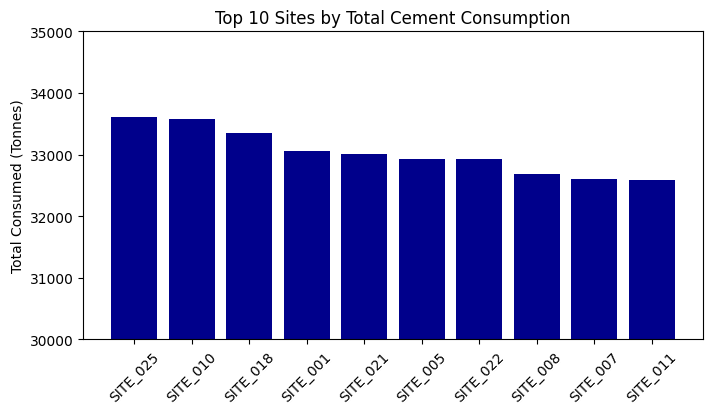

In [41]:
plt.figure(figsize=(8, 4))
plt.bar(top_sites['site_id'], top_sites['total_consumed'], color='darkblue')
plt.title('Top 10 Sites by Total Cement Consumption')
plt.ylim(30000, 35000)
plt.ylabel('Total Consumed (Tonnes)')
plt.xticks(rotation=45)
plt.show()

In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32880 entries, 0 to 32879
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      32880 non-null  datetime64[us]
 1   site_id                   32880 non-null  str           
 2   region                    32880 non-null  str           
 3   behavior                  32880 non-null  str           
 4   cement_type               32880 non-null  str           
 5   planned_pour_tonnes       32880 non-null  float64       
 6   consumed_tonnes           32880 non-null  float64       
 7   opening_inventory_tonnes  32880 non-null  float64       
 8   deliveries_tonnes         32880 non-null  float64       
 9   closing_inventory_tonnes  32880 non-null  float64       
 10  rain_mm                   32880 non-null  float64       
 11  avg_temp_c                32880 non-null  float64       
 12  silo_capacity             328

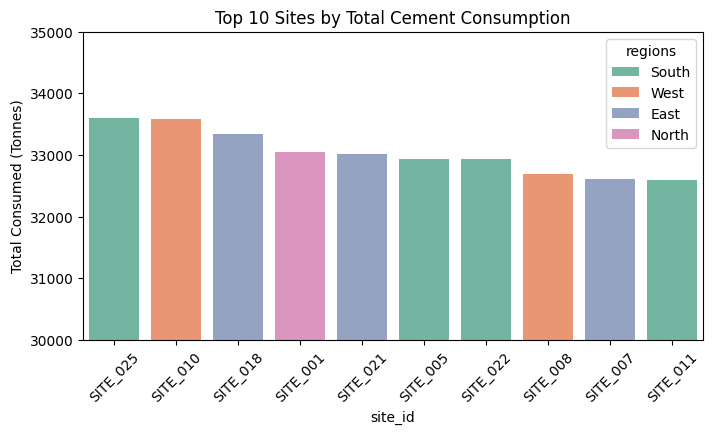

In [43]:
plt.figure(figsize=(8, 4))
sns.barplot(x='site_id', y='total_consumed', data=top_sites, hue='regions', dodge=False, palette='Set2')
plt.title('Top 10 Sites by Total Cement Consumption')
plt.ylim(30000, 35000)
plt.ylabel('Total Consumed (Tonnes)')
plt.xticks(rotation=45)
plt.show()

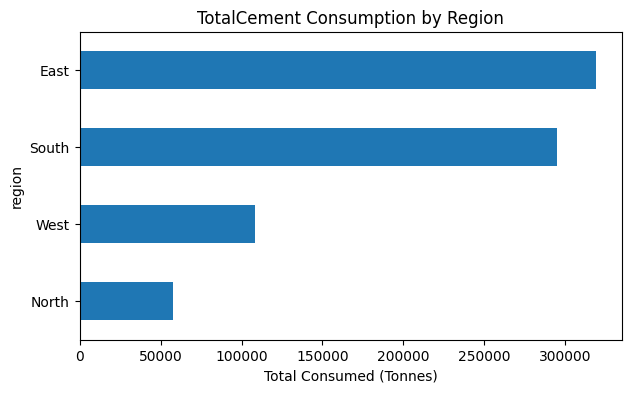

In [44]:
region_consumption = df.groupby('region')['consumed_tonnes'].sum().sort_values()
region_consumption.plot(kind='barh', figsize=(7,4), title='TotalCement Consumption by Region')
plt.xlabel('Total Consumed (Tonnes)')
plt.show()